# CAPSTONE 3, BANK MARKETING

Sebuah bank memiliki produk perbankan berupa deposito. Dalam menghadapi persaingan yang kompetitif antar bank, diperlukan metoda marketing yang tepat. 
Bank ingin mengetahui karakteristik pelanggan yang akan memiliki probabilitas lebih tinggi untuk membuka deposito sehingga target pemasaran atau marketing mejadi lebih spesifik. 
Dengan target yang lebih spesifik, sumber daya manusia dan financial yang dikeluarkan dapat lebih hemat dan efektik. 

Target:
1 = buka deposito
0 = tidak membuka deposito

Type 1 error : False positive
konsekuensi: alokasi sumber daya yang salah 

Type 2 error: False negative 
konsekuensi: kehilangan calon nasabah potensial 

In [24]:
# Core libraries
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    RobustScaler,
    OrdinalEncoder,
    FunctionTransformer,
)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

RANDOM_STATE = 2020
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)


In [25]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [26]:
import sklearn

print(sklearn.__version__)

1.7.2


In [27]:
df = pd.read_csv('data_bank_marketing_campaign.csv')

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7813 entries, 0 to 7812
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   age       7813 non-null   int64 
 1   job       7813 non-null   object
 2   balance   7813 non-null   int64 
 3   housing   7813 non-null   object
 4   loan      7813 non-null   object
 5   contact   7813 non-null   object
 6   month     7813 non-null   object
 7   campaign  7813 non-null   int64 
 8   pdays     7813 non-null   int64 
 9   poutcome  7813 non-null   object
 10  deposit   7813 non-null   object
dtypes: int64(4), object(7)
memory usage: 671.6+ KB


In [29]:
for col in df.columns:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False))


Column: age
age
31    351
32    344
30    329
35    324
33    317
     ... 
93      2
86      2
90      2
92      1
95      1
Name: count, Length: 75, dtype: int64

Column: job
job
management       1792
blue-collar      1346
technician       1291
admin.            936
services          658
retired           540
self-employed     280
unemployed        249
student           247
entrepreneur      236
housemaid         184
unknown            54
Name: count, dtype: int64

Column: balance
balance
0       546
1        28
3        21
2        20
5        17
       ... 
1920      1
4101      1
824       1
4654      1
5473      1
Name: count, Length: 3153, dtype: int64

Column: housing
housing
no     4140
yes    3673
Name: count, dtype: int64

Column: loan
loan
no     6789
yes    1024
Name: count, dtype: int64

Column: contact
contact
cellular     5628
unknown      1639
telephone     546
Name: count, dtype: int64

Column: month
month
may    1976
aug    1085
jul    1050
jun     857
apr     662
n

In [30]:
df.replace('unknown', np.nan, inplace=True)

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7813 entries, 0 to 7812
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   age       7813 non-null   int64 
 1   job       7759 non-null   object
 2   balance   7813 non-null   int64 
 3   housing   7813 non-null   object
 4   loan      7813 non-null   object
 5   contact   6174 non-null   object
 6   month     7813 non-null   object
 7   campaign  7813 non-null   int64 
 8   pdays     7813 non-null   int64 
 9   poutcome  1994 non-null   object
 10  deposit   7813 non-null   object
dtypes: int64(4), object(7)
memory usage: 671.6+ KB


In [32]:
((df.isnull().sum() / len(df)) * 100).round(2)

age          0.00
job          0.69
balance      0.00
housing      0.00
loan         0.00
contact     20.98
month        0.00
campaign     0.00
pdays        0.00
poutcome    74.48
deposit      0.00
dtype: float64

Diputuskan untuk tidak menggunakan variable poutcome dengan jumlah data unknown terlalu besar (74.48%) menggantikan nilai tersebut diperikirakan dapat menyebabkan bias dalam analisa data selanjutnya. 

In [33]:
df.to_csv('/Users/gustafdavid/Desktop/Purwadika/FOLDER FOR STUDENTS [Capstone Project Module 3]/cap 3/Bank Marketing Campaign/Bank_data_edit.csv', index=False)

In [34]:
possible_paths = [Path("Bank_data_edit.csv"), Path("/mnt/data/Bank_data_edit.csv")]
DATA_PATH = next((path for path in possible_paths if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Bank_data_edit.csv was not found. Place it in the same folder as this notebook."
    )

df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH}")
print(f"Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
display(df_raw.head())

Loaded: Bank_data_edit.csv
Shape: 7,813 rows × 11 columns


,age,job,balance,housing,loan,contact,month,campaign,pdays,poutcome,deposit
0,55,admin.,1662,no,no,cellular,jun,2,-1,NaN,yes
1,39,self-employed,-3058,yes,yes,cellular,apr,3,-1,NaN,yes
2,51,admin.,3025,no,no,cellular,may,1,352,other,yes
3,38,services,-87,yes,no,cellular,may,1,-1,NaN,no
4,36,housemaid,205,yes,no,telephone,nov,4,-1,NaN,no


In [35]:
display(pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isna().sum(),
    "missing_%": (df_raw.isna().mean() * 100).round(2),
    "unique_non_null": df_raw.nunique(dropna=True),
}))
print("Exact duplicate rows:", int(df_raw.duplicated().sum()))
display(df_raw.describe(include="all").T)

,dtype,missing_count,missing_%,unique_non_null
age,int64,0,0.00,75
job,object,54,0.69,11
balance,int64,0,0.00,3153
housing,object,0,0.00,2
loan,object,0,0.00,2
contact,object,1639,20.98,2
month,object,0,0.00,12
campaign,int64,0,0.00,32
pdays,int64,0,0.00,422
poutcome,object,5819,74.48,3


Exact duplicate rows: 8


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,7813.0,NaN,NaN,NaN,41.257264,11.91971,18.0,32.0,39.0,49.0,95.0
job,7759,11,management,1792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,7813.0,NaN,NaN,NaN,1512.448611,3089.291831,-6847.0,127.0,549.0,1684.0,66653.0
housing,7813,2,no,4140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,7813,2,no,6789,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,6174,2,cellular,5628,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,7813,12,may,1976,NaN,NaN,NaN,NaN,NaN,NaN,NaN
campaign,7813.0,NaN,NaN,NaN,2.519775,2.727001,1.0,1.0,2.0,3.0,63.0
pdays,7813.0,NaN,NaN,NaN,51.40855,108.072739,-1.0,-1.0,-1.0,40.0,854.0
poutcome,1994,3,failure,848,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [36]:
df = df_raw.copy()

,count,share_pct
deposit,,
no,4081,52.23
yes,3732,47.77


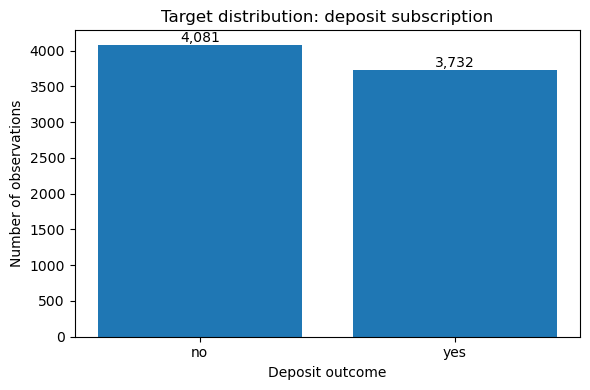

In [37]:
if "deposit" not in df.columns:
    raise KeyError("The target column 'deposit' is not present in the CSV.")

target_counts = df["deposit"].value_counts(dropna=False)
target_share = (df["deposit"].value_counts(normalize=True, dropna=False) * 100).round(2)
display(pd.DataFrame({"count": target_counts, "share_pct": target_share}))

fig, ax = plt.subplots(figsize=(6, 4))
counts = df["deposit"].value_counts().reindex(["no", "yes"])
ax.bar(counts.index.astype(str), counts.values)
ax.set_title("Target distribution: deposit subscription")
ax.set_xlabel("Deposit outcome")
ax.set_ylabel("Number of observations")
for i, value in enumerate(counts.values):
    ax.text(i, value, f"{value:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

# Analisa data numerik


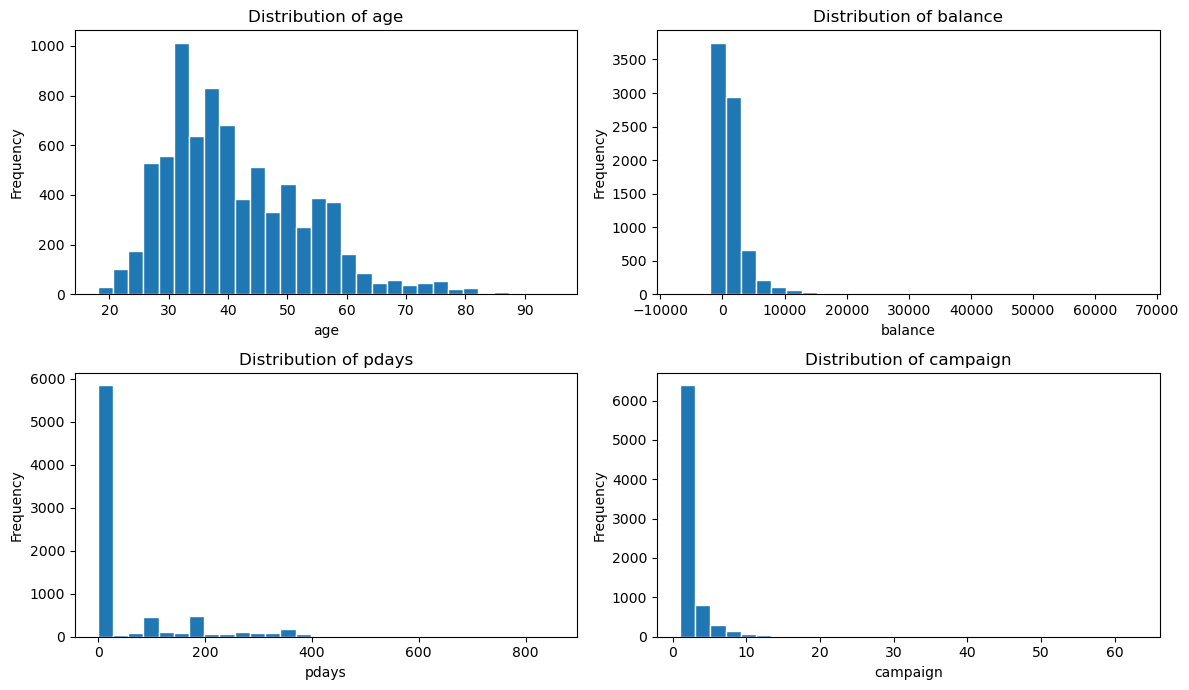

,count,mean,std,min,25%,50%,75%,max
age,7813.0,41.26,11.92,18.0,32.0,39.0,49.0,95.0
balance,7813.0,1512.45,3089.29,-6847.0,127.0,549.0,1684.0,66653.0
pdays,7813.0,51.41,108.07,-1.0,-1.0,-1.0,40.0,854.0
campaign,7813.0,2.52,2.73,1.0,1.0,2.0,3.0,63.0


In [38]:
#Analisa data numerik
NUMERIC_FEATURES = ["age", "balance", "pdays", "campaign"]
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    ax.hist(df[col].dropna(), bins=30, edgecolor="white")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

display(df[NUMERIC_FEATURES].describe().T.round(2))

semua data numerik tidak terdistribusi normal

# Analisa Data kategorikal

In [39]:
for col in ["housing", "loan", "contact"]:
    rate = df.groupby(col, dropna=False)["deposit"].apply(lambda s: s.eq("yes").mean() * 100)
    display(rate.rename("deposit_yes_rate_pct").round(1).to_frame().sort_values("deposit_yes_rate_pct", ascending=False))

,deposit_yes_rate_pct
housing,
no,57.7
yes,36.6


,deposit_yes_rate_pct
loan,
no,50.1
yes,32.2


,deposit_yes_rate_pct
contact,
cellular,55.1
telephone,49.5
NaN,22.1


# Data cleaning and preprocessing 
• missing value : contact, job with modus

• one hot encoding : housing, loan, contact

• binary encoding : job, month

• robust scalling : age, balance,pdays,campaign

• drop: poutcome

In [40]:
# Define the exact feature set requested in the project brief.
FEATURES = [
    "age", "balance", "pdays", "campaign",
    "job", "housing", "loan", "contact", "month",
]
TARGET = "deposit"
DROPPED_FEATURES = ["poutcome"]

required_columns = FEATURES + [TARGET] + DROPPED_FEATURES
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

# Explicitly drop poutcome, then select only the requested predictors and target.
df_model = df.drop(columns=DROPPED_FEATURES).copy()
X = df_model[FEATURES].copy()
y = df_model[TARGET].map({"no": 0, "yes": 1})

if y.isna().any():
    raise ValueError("Target contains missing or unexpected values after mapping.")
if set(y.unique()) != {0, 1}:
    raise ValueError(f"Expected binary target values {{0, 1}}, found {set(y.unique())}")

print("Selected feature columns:", FEATURES)
print("Dropped columns:", DROPPED_FEATURES)
print("X shape:", X.shape, "| y shape:", y.shape)
print("Target mapping: no=0, yes=1")

Selected feature columns: ['age', 'balance', 'pdays', 'campaign', 'job', 'housing', 'loan', 'contact', 'month']
Dropped columns: ['poutcome']
X shape: (7813, 9) | y shape: (7813,)
Target mapping: no=0, yes=1


In [41]:
CATEGORICAL_ONEHOT = ["housing", "loan"]
JOB_FEATURE = ["job"]
CONTACT_FEATURE = ["contact"]
MONTH_FEATURE = ["month"]

# Four bits provide 16 possible codes (0 through 15). Code 15 is reserved
# for a category that was not observed when the OrdinalEncoder was fitted.
BINARY_CODE_BITS = 4
UNKNOWN_CATEGORY_CODE = 2 ** BINARY_CODE_BITS - 1


def make_binary_encoding_pipeline(impute_missing=False):
    """Build a binary-encoding pipeline using only built-in transformers.

    OrdinalEncoder learns category-to-integer mappings from the training fold.
    FunctionTransformer then converts each uint8 code into four binary bits.
    """
    steps = []
    if impute_missing:
        steps.append(("imputer", SimpleImputer(strategy="most_frequent")))
    steps.extend([
        (
            "ordinal",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=UNKNOWN_CATEGORY_CODE,
                dtype=np.uint8,
            ),
        ),
        (
            "to_bits",
            FunctionTransformer(
                np.unpackbits,
                kw_args={
                    "axis": 1,
                    "bitorder": "little",
                    "count": BINARY_CODE_BITS,
                },
                validate=False,
            ),
        ),
    ])
    return Pipeline(steps=steps)


def build_preprocessor():
    """Create a fresh preprocessing pipeline for each model / CV fit."""
    job_pipeline = make_binary_encoding_pipeline(impute_missing=True)
    month_pipeline = make_binary_encoding_pipeline(impute_missing=True)

    contact_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    return ColumnTransformer(
        transformers=[
            ("numeric", RobustScaler(), NUMERIC_FEATURES),
            ("job_binary", job_pipeline, JOB_FEATURE),
            ("month_binary", month_pipeline, MONTH_FEATURE),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_ONEHOT),
            ("contact", contact_pipeline, CONTACT_FEATURE),
        ],
        remainder="drop",
        verbose_feature_names_out=True,
    )


def build_pipeline(estimator):
    """Combine preprocessing with a supplied classifier."""
    return Pipeline(steps=[
        ("preprocess", build_preprocessor()),
        ("classifier", estimator),
    ])

# Structural checks: all encoding stages use built-in sklearn / NumPy tools.
preprocessing_template = build_preprocessor()
print(preprocessing_template)
print(f"Binary-encoding width: {BINARY_CODE_BITS} bits per feature")
print(f"Reserved unseen-category code: {UNKNOWN_CATEGORY_CODE}")

ColumnTransformer(transformers=[('numeric', RobustScaler(),
                                 ['age', 'balance', 'pdays', 'campaign']),
                                ('job_binary',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('ordinal',
                                                  OrdinalEncoder(dtype=<class 'numpy.uint8'>,
                                                                 handle_unknown='use_encoded_value',
                                                                 unknown_value=15)),
                                                 ('to_bits',
                                                  FunctionTransformer(func=<function unpackbits at 0x1176ff...
                                                  FunctionTransformer(func=<function unpackbits at 0x1176ff0f0>,
                                       

# Split data set Train - Test

In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

split_summary = pd.DataFrame({
    "partition": ["Train", "Test", "Full dataset"],
    "rows": [len(y_train), len(y_test), len(y)],
    "deposit_yes_pct": [
        (y_train.mean() * 100),
        (y_test.mean() * 100),
        (y.mean() * 100),
    ],
})
display(split_summary.round(2))

,partition,rows,deposit_yes_pct
0,Train,6250,47.76
1,Test,1563,47.79
2,Full dataset,7813,47.77


# Base model classification

In [43]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
}

baseline_estimators = {
    "Logistic Regression": LogisticRegression(
        solver="liblinear", C=1.0, max_iter=1000, random_state=RANDOM_STATE
    ),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree (entropy, depth=5)": DecisionTreeClassifier(
        criterion="entropy", max_depth=5, random_state=RANDOM_STATE
    ),
}

cv_rows = []
cv_details = {}
for model_name, estimator in baseline_estimators.items():
    pipeline = build_pipeline(estimator)
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv5,
        scoring=SCORING,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise",
    )
    cv_details[model_name] = scores
    row = {"model": model_name}
    for metric in SCORING:
        values = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=1)
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).sort_values("f1_mean", ascending=False).reset_index(drop=True)
display(cv_results.round(4))


,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std
0,Logistic Regression,0.6549,0.0227,0.6418,0.0234,0.6275,0.0295,0.6345,0.0257,0.7013,0.0269,0.6839,0.0152
1,KNN (k=5),0.6549,0.0068,0.6547,0.0099,0.5873,0.0128,0.6191,0.0079,0.6894,0.0135,0.6590,0.0141
2,"Decision Tree (entropy, depth=5)",0.6755,0.0152,0.7519,0.0535,0.4888,0.0670,0.5881,0.0344,0.7093,0.0266,0.6890,0.0222


berdasarkan nilai recall, precision, dan F1 -> model yang dipilih adalah logistic regression 

In [44]:
baseline_lr = build_pipeline(
    LogisticRegression(
        solver="liblinear", C=1.0, max_iter=1000, random_state=RANDOM_STATE
    )
)
baseline_lr.fit(X_train, y_train)

baseline_test_pred = baseline_lr.predict(X_test)
baseline_test_prob = baseline_lr.predict_proba(X_test)[:, 1]


def calculate_metrics(y_true, y_pred, y_probability):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_probability),
        "average_precision": average_precision_score(y_true, y_probability),
    }

baseline_test_metrics = calculate_metrics(y_test, baseline_test_pred, baseline_test_prob)
display(pd.Series(baseline_test_metrics, name="baseline_test_score").to_frame().round(4))
print(classification_report(
    y_test,
    baseline_test_pred,
    target_names=["no deposit", "deposit"],
    zero_division=0,
))

,baseline_test_score
accuracy,0.6366
precision,0.6211
recall,0.6145
f1,0.6178
roc_auc,0.6828
average_precision,0.6653


              precision    recall  f1-score   support

  no deposit       0.65      0.66      0.65       816
     deposit       0.62      0.61      0.62       747

    accuracy                           0.64      1563
   macro avg       0.64      0.64      0.64      1563
weighted avg       0.64      0.64      0.64      1563



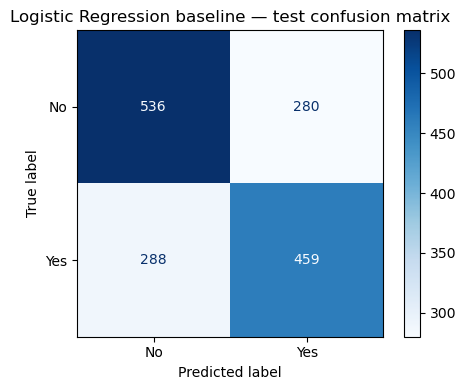

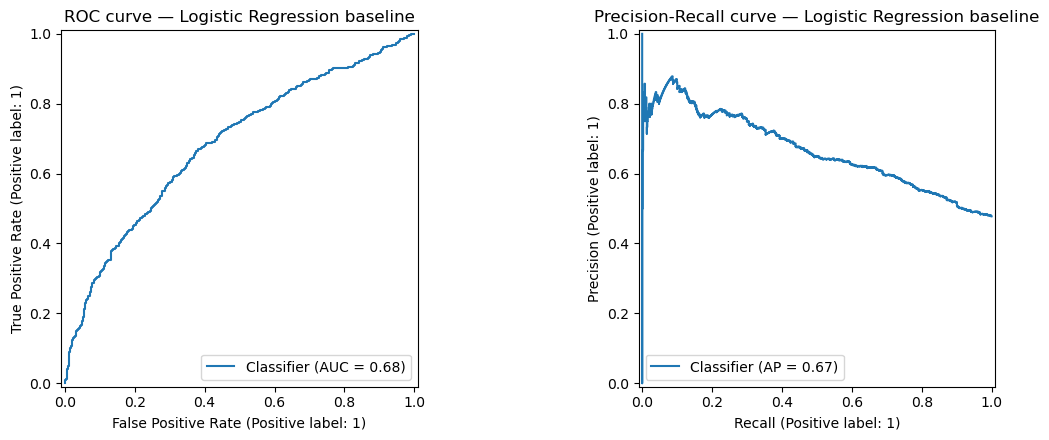

In [45]:
# Confusion matrix: actual rows, predicted columns.
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_test_pred,
    display_labels=["No", "Yes"],
    cmap="Blues",
    values_format="d",
    ax=ax,
)
ax.set_title("Logistic Regression baseline — test confusion matrix")
plt.tight_layout()
plt.show()

# ROC curve and Precision-Recall curve.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
RocCurveDisplay.from_predictions(y_test, baseline_test_prob, ax=axes[0])
axes[0].set_title("ROC curve — Logistic Regression baseline")
PrecisionRecallDisplay.from_predictions(y_test, baseline_test_prob, ax=axes[1])
axes[1].set_title("Precision-Recall curve — Logistic Regression baseline")
plt.tight_layout()
plt.show()

# Logistic Regression Hyperparameter Tuning

split data training (80%) menjadi 60% train and 20% validation 


In [46]:
X_train_60, X_valid_20, y_train_60, y_valid_20 = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_train,
)

print("Train rows (approx. 60%):", len(X_train_60))
print("Validation rows (approx. 20%):", len(X_valid_20))
print("Test rows (approx. 20%):", len(X_test))

C_candidates = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0, 100.0]
validation_rows = []

for C_value in C_candidates:
    candidate = build_pipeline(
        LogisticRegression(
            solver="liblinear", C=C_value, max_iter=1000, random_state=RANDOM_STATE
        )
    )
    candidate.fit(X_train_60, y_train_60)
    pred_valid = candidate.predict(X_valid_20)
    prob_valid = candidate.predict_proba(X_valid_20)[:, 1]
    row = {"C": C_value}
    row.update(calculate_metrics(y_valid_20, pred_valid, prob_valid))
    validation_rows.append(row)

simple_tuning_results = pd.DataFrame(validation_rows).sort_values(
    ["f1", "recall", "precision"], ascending=False
).reset_index(drop=True)
best_C_simple = float(simple_tuning_results.loc[0, "C"])

display(simple_tuning_results.round(4))
print(f"Selected C based on validation F1: {best_C_simple}")

Train rows (approx. 60%): 4687
Validation rows (approx. 20%): 1563
Test rows (approx. 20%): 1563


,C,accuracy,precision,recall,f1,roc_auc,average_precision
0,5.00,0.6583,0.6468,0.6260,0.6362,0.7017,0.6788
1,10.00,0.6583,0.6468,0.6260,0.6362,0.7017,0.6788
2,20.00,0.6583,0.6468,0.6260,0.6362,0.7017,0.6788
3,100.00,0.6583,0.6468,0.6260,0.6362,0.7017,0.6788
4,0.50,0.6571,0.6450,0.6260,0.6354,0.7017,0.6791
5,1.00,0.6577,0.6463,0.6247,0.6353,0.7017,0.6789
6,2.00,0.6577,0.6463,0.6247,0.6353,0.7017,0.6789
7,0.10,0.6564,0.6441,0.6260,0.6349,0.7016,0.6794
8,0.01,0.6507,0.6377,0.6206,0.6291,0.7008,0.6819


Selected C based on validation F1: 5.0


# GridSearch Hyperparameter Tuning

In [47]:
grid_pipeline = build_pipeline(
    LogisticRegression(solver="liblinear", random_state=RANDOM_STATE)
)
param_grid = {
    "classifier__C": [0.01, 0.1, 1.0, 10.0, 100.0],
    "classifier__max_iter": [100, 300, 500, 1000],
}

grid_search = GridSearchCV(
    estimator=grid_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv5,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    error_score="raise",
)
grid_search.fit(X_train, y_train)

print("Best GridSearchCV parameters:", grid_search.best_params_)
print("Best mean CV F1:", round(grid_search.best_score_, 4))

grid_cv_results = pd.DataFrame(grid_search.cv_results_)
grid_summary = grid_cv_results[[
    "param_classifier__C",
    "param_classifier__max_iter",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]].sort_values(["rank_test_score", "param_classifier__C"])
display(grid_summary.head(15).round(4))

Best GridSearchCV parameters: {'classifier__C': 0.01, 'classifier__max_iter': 100}
Best mean CV F1: 0.6354


,param_classifier__C,param_classifier__max_iter,mean_test_score,std_test_score,rank_test_score
0,0.01,100,0.6354,0.0210,1
1,0.01,300,0.6354,0.0210,1
2,0.01,500,0.6354,0.0210,1
3,0.01,1000,0.6354,0.0210,1
4,0.10,100,0.6351,0.0235,5
5,0.10,300,0.6351,0.0235,5
6,0.10,500,0.6351,0.0235,5
7,0.10,1000,0.6351,0.0235,5
12,10.00,100,0.6349,0.0227,9
13,10.00,300,0.6349,0.0227,9


- C = 5 hyperparameter  
- max_iter = 4 hyperparameter
- model = 20 kombinasi model

- CV = 5 fold --> **100 training model**

In [49]:
grid_best_model = grid_search.best_estimator_

grid_test_pred = grid_best_model.predict(X_test)
grid_test_prob = grid_best_model.predict_proba(X_test)[:, 1]
grid_test_metrics = calculate_metrics(y_test, grid_test_pred, grid_test_prob)

grid_comparison = pd.DataFrame([
    {"model": "Before tuning (C=1, max_iter=1000)", **baseline_test_metrics},
    {"model": "After GridSearchCV", **grid_test_metrics},
]).set_index("model")
display(grid_comparison.round(4))

delta = grid_comparison.loc["After GridSearchCV"] - grid_comparison.loc[
    "Before tuning (C=1, max_iter=1000)"
]


,accuracy,precision,recall,f1,roc_auc,average_precision
model,,,,,,
"Before tuning (C=1, max_iter=1000)",0.6366,0.6211,0.6145,0.6178,0.6828,0.6653
After GridSearchCV,0.6315,0.6157,0.6091,0.6124,0.6815,0.6640
